# Model 2 — Riemannian Geometry Results

- **2A:** covariances (LWF) → tangent space → shrinkage LDA
- **2B:** 2A + per-domain Riemannian recentering (not run within-subject: no-op)

**Band / window:** 8–30 Hz · 0.5–2.5 s post-cue
**Evaluation:** Within = LORO (3 folds) · Cross = GroupKFold-5 · Transfer = executed → imagined
**Stats:** permutation tests (Within N=200, Cross/Transfer N=1000) · BH-FDR (α=0.05)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
from scipy.stats import wilcoxon

# ── Paths ─────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
M2_RESULTS = NOTEBOOK_DIR.parent / "modeling" / "02_riemannian" / "results"
FIGURES    = NOTEBOOK_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

# ── Load Model 2 CSVs ────────────────────────────────────────────────────
# Within-subject: 2A only (2B is no-op within one subject)
w1 = pd.read_csv(M2_RESULTS / "model2_task1_LR_within_subject.csv")
w2 = pd.read_csv(M2_RESULTS / "model2_task2_FF_within_subject.csv")
cx1 = pd.read_csv(M2_RESULTS / "model2_task1_LR_cross_subject.csv")           # per subject
cx2 = pd.read_csv(M2_RESULTS / "model2_task2_FF_cross_subject.csv")
cf1 = pd.read_csv(M2_RESULTS / "model2_task1_LR_cross_subject_perfold.csv")   # per fold (5 rows)
cf2 = pd.read_csv(M2_RESULTS / "model2_task2_FF_cross_subject_perfold.csv")
cx1_pooled = pd.read_csv(M2_RESULTS / "model2_task1_LR_cross_subject_pooled.csv").set_index("variant")
cx2_pooled = pd.read_csv(M2_RESULTS / "model2_task2_FF_cross_subject_pooled.csv").set_index("variant")
tr1 = pd.read_csv(M2_RESULTS / "model2_transfer_task1_LR.csv")
tr2 = pd.read_csv(M2_RESULTS / "model2_transfer_task2_FF.csv")

# ── Shorten m2a_/m2b_ prefixes to a_/b_ ─────────────────────────────────────
def rename_variants(df):
    return df.rename(columns={c: c.replace("m2a_", "a_").replace("m2b_", "b_") for c in df.columns})

cx1, cx2, cf1, cf2, tr1, tr2 = map(rename_variants, (cx1, cx2, cf1, cf2, tr1, tr2))
# Cross: per-subject FDR from cross_subject_permtest.py
SIG = pd.read_csv(NOTEBOOK_DIR / "cross_subject_persubject_significance.csv")   # from cross_subject_permtest.py

def cross_fdr(variant, task):
    return SIG[(SIG.variant == variant) & (SIG.task == task)][["subject", "fdr_sig"]]
for df, task in [(cx1, "T1"), (cx2, "T2")]:
    for pre, variant in [("a_", "M2A-Riemann"), ("b_", "M2B-Riemann-aligned")]:
        df[f"{pre}fdr_sig"] = df[["subject"]].merge(cross_fdr(variant, task), on="subject")["fdr_sig"].astype(int).values

w1["fdr_sig"] = w1["perm_pvalue_fdr_sig"]
w2["fdr_sig"] = w2["perm_pvalue_fdr_sig"]

# ── Summary table ──────────────────────────────────────────────────────────
def table_row(label, variant, acc, bal, auc, kappa, sens, spec, group_p, fdr):
    return {"Experiment": label, "Variant": variant,
            "Acc": round(acc, 3), "Bal.Acc": round(bal, 3), "AUC": round(auc, 3), "Kappa": round(kappa, 3),
            "Sensitivity": round(sens, 3), "Specificity": round(spec, 3),
            "Group p": f"{group_p:.2g}", "FDR sig": fdr}

rows = []
for df, label in [(w1, "Within T1 (L/R fist)"), (w2, "Within T2 (Fists/Feet)")]:
    _, gp = wilcoxon(df["acc"] - 0.5)
    rows.append(table_row(label, "2A", df["acc"].mean(), df["bal_acc"].mean(), df["auc"].mean(),
                          df["kappa"].mean(), df["sensitivity"].mean(), df["specificity"].mean(),
                          gp, f"{int(df['fdr_sig'].sum())}/106"))
for pooled_df, cx, label in [(cx1_pooled, cx1, "Cross T1 (L/R fist)"), (cx2_pooled, cx2, "Cross T2 (Fists/Feet)")]:
    for variant, key, pre in [("2A", "m2a", "a_"), ("2B", "m2b", "b_")]:
        p = pooled_df.loc[key]
        rows.append(table_row(label, variant, p["acc"], p["bal_acc"], p["auc"], p["kappa"],
                              p["sensitivity"], p["specificity"], p["perm_pvalue"],
                              f"{int(cx[f'{pre}fdr_sig'].sum())}/106"))
for df, label in [(tr1, "Transfer T1 (L/R fist)"), (tr2, "Transfer T2 (Fists/Feet)")]:
    for variant, pre in [("2A", "a_"), ("2B", "b_")]:
        _, gp = wilcoxon(df[f"{pre}acc"] - 0.5)
        rows.append(table_row(label, variant, df[f"{pre}acc"].mean(), df[f"{pre}bal_acc"].mean(),
                              df[f"{pre}auc"].mean(), df[f"{pre}kappa"].mean(),
                              df[f"{pre}sensitivity"].mean(), df[f"{pre}specificity"].mean(),
                              gp, f"{int(df[f'{pre}perm_fdr_sig'].sum())}/106"))

summary = pd.DataFrame(rows).set_index(["Experiment", "Variant"])
print("=" * 90)
print("Model 2 (Riemannian) — Summary Statistics")
print("(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)")
print("(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)")
print("=" * 90)
display(summary)

# ── Wilcoxon: 2B vs 2A (per-subject paired) ─────────────────────────────────
print("\nWilcoxon 2B vs 2A, per subject (paired, n=106 subjects):")
for df, label in [(cx1, "Cross T1"), (cx2, "Cross T2"), (tr1, "Transfer T1"), (tr2, "Transfer T2")]:
    _, p = wilcoxon(df["b_acc"], df["a_acc"])
    d = (df["b_acc"] - df["a_acc"]).mean()
    print(f"  {label:<12}: mean diff={d:+.3f}  p={p:.2g}  ({(df['b_acc'] > df['a_acc']).sum()}/106 subjects improved)")


Model 2 (Riemannian) — Summary Statistics
(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)
(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)


Acc  Bal.Acc  ...  Group p  FDR sig
Experiment               Variant                  ...                  
Within T1 (L/R fist)     2A       0.598    0.596  ...  6.5e-12   22/106
Within T2 (Fists/Feet)   2A       0.645    0.644  ...    1e-14   47/106
Cross T1 (L/R fist)      2A       0.577    0.577  ...    0.001    5/106
                         2B       0.618    0.618  ...    0.001   29/106
Cross T2 (Fists/Feet)    2A       0.594    0.594  ...    0.001   18/106
                         2B       0.641    0.641  ...    0.001   35/106
Transfer T1 (L/R fist)   2A       0.590    0.590  ...  6.6e-12   19/106
                         2B       0.602    0.602  ...    4e-11   25/106
Transfer T2 (Fists/Feet) 2A       0.628    0.627  ...  3.7e-15   39/106
                         2B       0.663    0.664  ...    4e-17   44/106

[10 rows x 8 columns]


Wilcoxon 2B vs 2A, per subject (paired, n=106 subjects):
  Cross T1    : mean diff=+0.041  p=1.4e-06  (66/106 subjects improved)
  Cross T2    : mean diff=+0.047  p=1.2e-07  (64/106 subjects improved)
  Transfer T1 : mean diff=+0.012  p=0.067  (53/106 subjects improved)
  Transfer T2 : mean diff=+0.035  p=3.3e-06  (63/106 subjects improved)


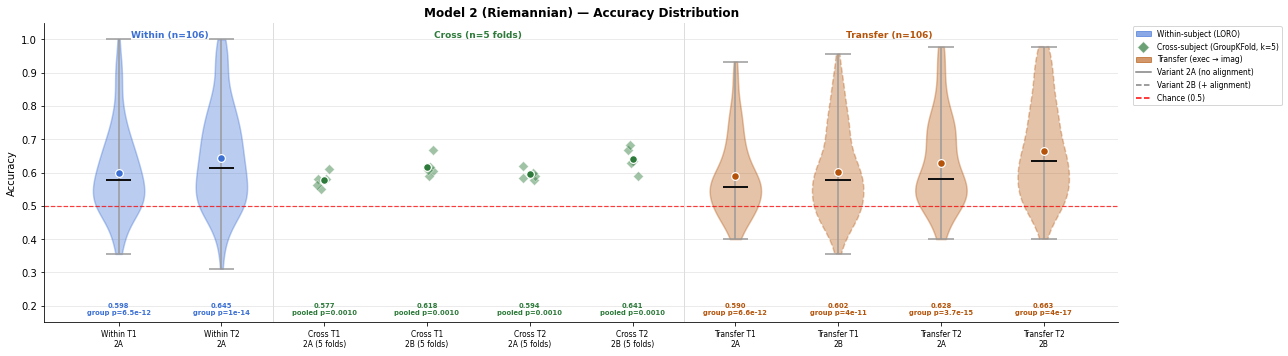

Saved model2_accuracy_violin.png


In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Within/Transfer: violins (n=106); Cross: jittered folds (n=5).
# 6th element: group-level p-value (Cross pooled perm; else Wilcoxon vs chance).
vdata = [
    (w1["acc"].values,      "Within T1\n2A",       "#3b6fd4", "-",  False, None),
    (w2["acc"].values,      "Within T2\n2A",       "#3b6fd4", "-",  False, None),
    (cf1["a_acc"].values,   "Cross T1\n2A (5 folds)", "#2d7a3a", "-",  True,  float(cx1_pooled.loc["m2a","perm_pvalue"])),
    (cf1["b_acc"].values,   "Cross T1\n2B (5 folds)", "#2d7a3a", "--", True,  float(cx1_pooled.loc["m2b","perm_pvalue"])),
    (cf2["a_acc"].values,   "Cross T2\n2A (5 folds)", "#2d7a3a", "-",  True,  float(cx2_pooled.loc["m2a","perm_pvalue"])),
    (cf2["b_acc"].values,   "Cross T2\n2B (5 folds)", "#2d7a3a", "--", True,  float(cx2_pooled.loc["m2b","perm_pvalue"])),
    (tr1["a_acc"].values,   "Transfer T1\n2A",     "#b45309", "-",  False, None),
    (tr1["b_acc"].values,   "Transfer T1\n2B",     "#b45309", "--", False, None),
    (tr2["a_acc"].values,   "Transfer T2\n2A",     "#b45309", "-",  False, None),
    (tr2["b_acc"].values,   "Transfer T2\n2B",     "#b45309", "--", False, None),
]

fig, ax = plt.subplots(figsize=(18, 5))
positions = np.arange(1, len(vdata) + 1)

violin_positions = [p for p, (_, _, _, _, is_fold, _) in zip(positions, vdata) if not is_fold]
violin_data       = [d[0] for d in vdata if not d[4]]
violin_colors     = [d[2] for d in vdata if not d[4]]
violin_styles     = [d[3] for d in vdata if not d[4]]

parts = ax.violinplot(violin_data, positions=violin_positions, showmedians=True, showextrema=True)
for pc, color, ls in zip(parts["bodies"], violin_colors, violin_styles):
    pc.set_facecolor(color); pc.set_alpha(0.35); pc.set_edgecolor(color)
    pc.set_linestyle(ls); pc.set_linewidth(1.5)
parts["cmedians"].set_color("#111"); parts["cmedians"].set_linewidth(2)
for key in ("cmaxes", "cmins", "cbars"):
    parts[key].set_color("#999")

rng = np.random.default_rng(0)
for pos, (vals, label, color, ls, is_fold, pooled_p) in zip(positions, vdata):
    if is_fold:
        jitter = rng.uniform(-0.07, 0.07, size=len(vals))
        ax.scatter(np.full(len(vals), pos) + jitter, vals, color=color, alpha=0.45, s=50,
                   marker="D", edgecolors="white", linewidth=0.7, zorder=3)

for i, (vals, label, color, ls, is_fold, pooled_p) in enumerate(vdata):
    ax.scatter(positions[i], vals.mean(), color=color, s=60, zorder=5,
               edgecolors="white", linewidth=1.2)
    if pooled_p is not None:
        sig_txt = f"pooled p={pooled_p:.4f}"
    else:
        _, group_p = wilcoxon(vals - 0.5)
        sig_txt = f"group p={group_p:.2g}"
    ax.text(positions[i], 0.17, f"{vals.mean():.3f}\n{sig_txt}", ha="center", va="bottom", fontsize=6.8, color=color, fontweight="bold")

ax.axhline(0.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75)

for sep in [2.5, 6.5]:
    ax.axvline(sep, color="#ddd", linewidth=1)
for xp, lbl, col in [(1.5,"Within (n=106)","#3b6fd4"),(4.5,"Cross (n=5 folds)","#2d7a3a"),(8.5,"Transfer (n=106)","#b45309")]:
    ax.text(xp, 0.95, lbl, ha="center", transform=ax.get_xaxis_transform(),
            fontsize=9, color=col, fontweight="bold")

ax.set_xticks(positions)
ax.set_xticklabels([d[1] for d in vdata], fontsize=7.5)
ax.set_ylabel("Accuracy", fontsize=10)
ax.set_ylim(0.15, 1.05)
ax.set_title("Model 2 (Riemannian) — Accuracy Distribution", fontsize=12, fontweight="bold")
ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
legend_handles = [
    mpatches.Patch(color="#3b6fd4", alpha=0.6, label="Within-subject (LORO)"),
    plt.Line2D([0],[0], marker="D", color="w", markerfacecolor="#2d7a3a", markersize=8, alpha=0.7, label="Cross-subject (GroupKFold, k=5)"),
    mpatches.Patch(color="#b45309", alpha=0.6, label="Transfer (exec → imag)"),
    plt.Line2D([0],[0], color="gray", linestyle="-",  label="Variant 2A (no alignment)"),
    plt.Line2D([0],[0], color="gray", linestyle="--", label="Variant 2B (+ alignment)"),
    plt.Line2D([0],[0], color="red",  linestyle="--", label="Chance (0.5)"),
]
ax.legend(handles=legend_handles, fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True)
plt.tight_layout()
plt.savefig(FIGURES / "model2_accuracy_violin.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model2_accuracy_violin.png")

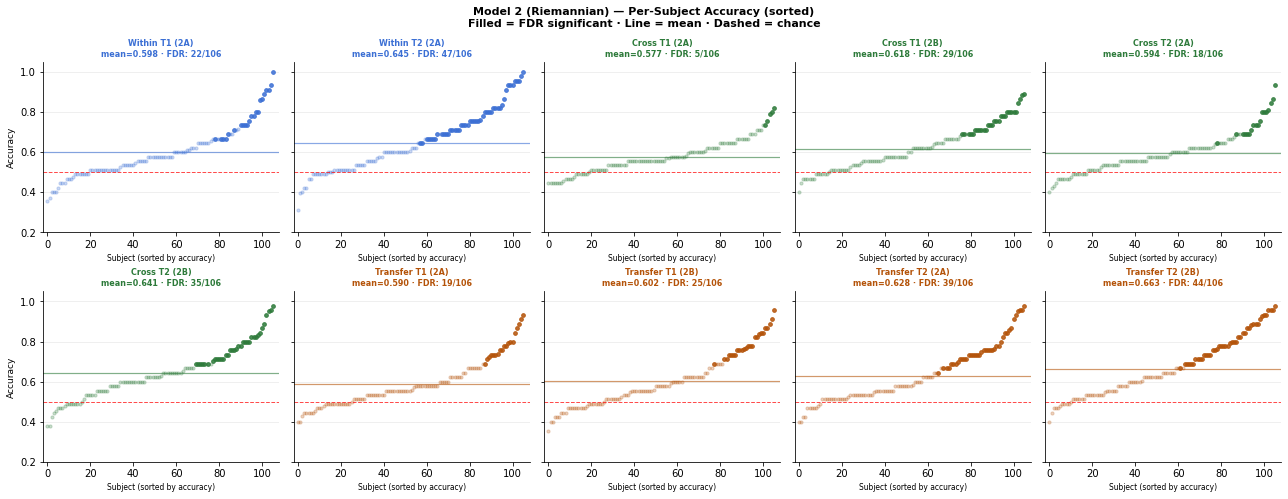

Saved model2_accuracy_dotplot.png


In [3]:
# Per-subject accuracy, sorted
dot_data = [
    (w1["acc"],    w1["fdr_sig"],         "Within T1 (2A)",   "#3b6fd4", None),
    (w2["acc"],    w2["fdr_sig"],         "Within T2 (2A)",   "#3b6fd4", None),
    (cx1["a_acc"], cx1["a_fdr_sig"],      "Cross T1 (2A)",    "#2d7a3a", None),
    (cx1["b_acc"], cx1["b_fdr_sig"],      "Cross T1 (2B)",    "#2d7a3a", None),
    (cx2["a_acc"], cx2["a_fdr_sig"],      "Cross T2 (2A)",    "#2d7a3a", None),
    (cx2["b_acc"], cx2["b_fdr_sig"],      "Cross T2 (2B)",    "#2d7a3a", None),
    (tr1["a_acc"], tr1["a_perm_fdr_sig"], "Transfer T1 (2A)", "#b45309", None),
    (tr1["b_acc"], tr1["b_perm_fdr_sig"], "Transfer T1 (2B)", "#b45309", None),
    (tr2["a_acc"], tr2["a_perm_fdr_sig"], "Transfer T2 (2A)", "#b45309", None),
    (tr2["b_acc"], tr2["b_perm_fdr_sig"], "Transfer T2 (2B)", "#b45309", None),
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
axes = axes.flatten()
for ax, (acc, sig, label, color, _) in zip(axes, dot_data):
    order  = np.argsort(acc.values)
    vals_s = acc.values[order]
    x = np.arange(len(vals_s))
    sig_s = sig.values[order]
    ax.scatter(x[sig_s == 0], vals_s[sig_s == 0], color=color, alpha=0.25, s=10)
    ax.scatter(x[sig_s == 1], vals_s[sig_s == 1], color=color, alpha=0.85, s=14)
    title_sig = f"FDR: {int(sig.sum())}/106"
    ax.axhline(0.5,           color="red", linestyle="--", linewidth=1, alpha=0.7)
    ax.axhline(vals_s.mean(), color=color, linestyle="-",  linewidth=1.2, alpha=0.6)
    ax.set_title(f"{label}\nmean={vals_s.mean():.3f} · {title_sig}", fontsize=8, fontweight="bold", color=color)
    ax.set_xlabel("Subject (sorted by accuracy)", fontsize=7.5)
    ax.set_xlim(-2, 108); ax.set_ylim(0.2, 1.05)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, alpha=0.25); ax.set_axisbelow(True)

axes[0].set_ylabel("Accuracy", fontsize=9)
axes[5].set_ylabel("Accuracy", fontsize=9)
fig.suptitle("Model 2 (Riemannian) — Per-Subject Accuracy (sorted)\n"
             "Filled = FDR significant · Line = mean · Dashed = chance",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "model2_accuracy_dotplot.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model2_accuracy_dotplot.png")


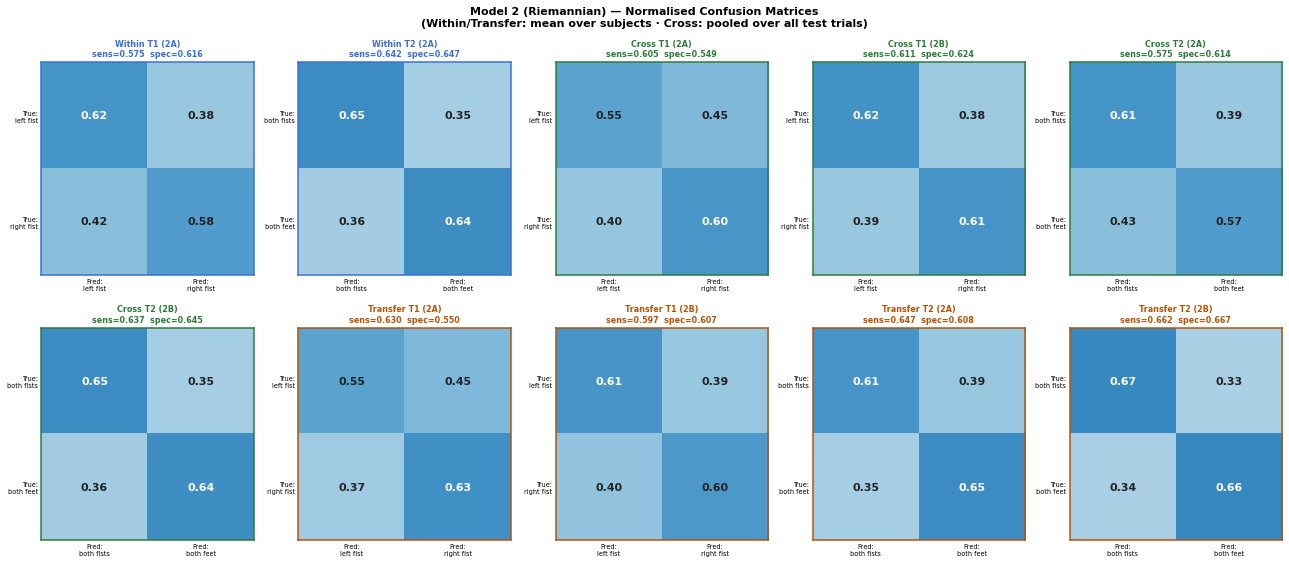

Saved model2_confusion_matrices.png


In [4]:
# Normalised confusion matrices (Cross: pooled values)
conf_data = [
    (w1,  "",   None,                  "Within T1 (2A)",   "#3b6fd4", ("left fist", "right fist")),
    (w2,  "",   None,                  "Within T2 (2A)",   "#3b6fd4", ("both fists", "both feet")),
    (cx1, "a_", cx1_pooled.loc["m2a"], "Cross T1 (2A)",    "#2d7a3a", ("left fist", "right fist")),
    (cx1, "b_", cx1_pooled.loc["m2b"], "Cross T1 (2B)",    "#2d7a3a", ("left fist", "right fist")),
    (cx2, "a_", cx2_pooled.loc["m2a"], "Cross T2 (2A)",    "#2d7a3a", ("both fists", "both feet")),
    (cx2, "b_", cx2_pooled.loc["m2b"], "Cross T2 (2B)",    "#2d7a3a", ("both fists", "both feet")),
    (tr1, "a_", None,                  "Transfer T1 (2A)", "#b45309", ("left fist", "right fist")),
    (tr1, "b_", None,                  "Transfer T1 (2B)", "#b45309", ("left fist", "right fist")),
    (tr2, "a_", None,                  "Transfer T2 (2A)", "#b45309", ("both fists", "both feet")),
    (tr2, "b_", None,                  "Transfer T2 (2B)", "#b45309", ("both fists", "both feet")),
]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()
for ax, (df, pre, pooled_row, label, color, (cls0, cls1)) in zip(axes, conf_data):
    if pooled_row is not None:
        sens, spec = pooled_row["sensitivity"], pooled_row["specificity"]
    else:
        sens, spec = df[f"{pre}sensitivity"].mean(), df[f"{pre}specificity"].mean()
    cm = np.array([[spec, 1 - spec], [1 - sens, sens]])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{cm[r, c]:.2f}", ha="center", va="center", fontsize=11, fontweight="bold",
                    color="white" if cm[r, c] > 0.6 else "#222")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels([f"Pred:\n{cls0}", f"Pred:\n{cls1}"], fontsize=6.5)
    ax.set_yticklabels([f"True:\n{cls0}", f"True:\n{cls1}"], fontsize=6.5)
    ax.set_title(f"{label}\nsens={sens:.3f}  spec={spec:.3f}", fontsize=8, fontweight="bold", color=color, pad=6)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(1.5)

fig.suptitle("Model 2 (Riemannian) — Normalised Confusion Matrices\n"
             "(Within/Transfer: mean over subjects · Cross: pooled over all test trials)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "model2_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model2_confusion_matrices.png")


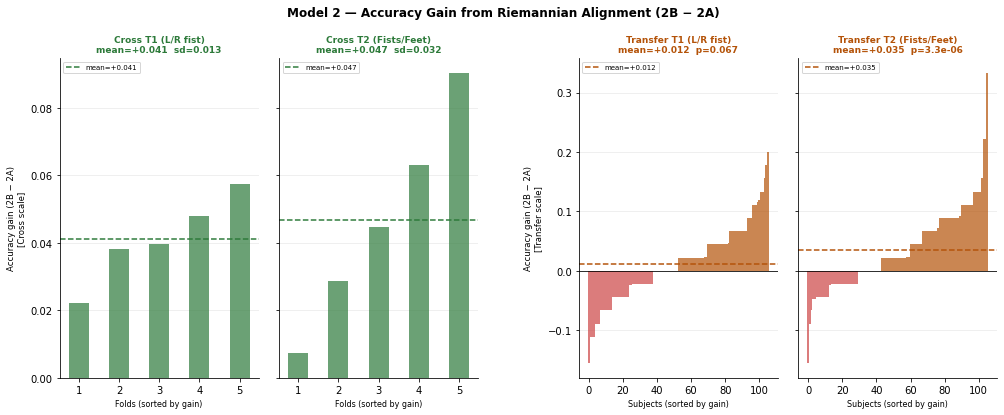

Saved model2_alignment_gain.png


In [5]:
import matplotlib.gridspec as gridspec

# Alignment gain (2B - 2A). Cross: per fold (n=5, mean only); Transfer: per subject (Wilcoxon).
# Separate y-axes per pair.
gain_data = [
    (cf1["b_acc"] - cf1["a_acc"], "Cross T1 (L/R fist)",      "#2d7a3a", "fold"),
    (cf2["b_acc"] - cf2["a_acc"], "Cross T2 (Fists/Feet)",    "#2d7a3a", "fold"),
    (tr1["b_acc"] - tr1["a_acc"], "Transfer T1 (L/R fist)",   "#b45309", "subject"),
    (tr2["b_acc"] - tr2["a_acc"], "Transfer T2 (Fists/Feet)", "#b45309", "subject"),
]

fig = plt.figure(figsize=(14, 6))
gs = gridspec.GridSpec(1, 5, width_ratios=[1, 1, 0.3, 1, 1], wspace=0.12)
ax_c1 = fig.add_subplot(gs[0, 0])
ax_c2 = fig.add_subplot(gs[0, 1], sharey=ax_c1)
ax_t1 = fig.add_subplot(gs[0, 3])
ax_t2 = fig.add_subplot(gs[0, 4], sharey=ax_t1)
axes = [ax_c1, ax_c2, ax_t1, ax_t2]

for ax, (gain, label, color, unit) in zip(axes, gain_data):
    order = np.argsort(gain.values)
    vals  = gain.values[order]
    x     = np.arange(len(vals))
    colors_bar = [color if v > 0 else "#cc4444" for v in vals]
    bar_width = 0.5 if unit == "fold" else 1.0
    ax.bar(x, vals, color=colors_bar, alpha=0.7, width=bar_width)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axhline(gain.mean(), color=color, linewidth=1.5, linestyle="--",
               label=f"mean={gain.mean():+.3f}")
    if unit == "subject":
        _, p = wilcoxon(gain)
        stat_txt = f"mean={gain.mean():+.3f}  p={p:.2g}"
    else:
        stat_txt = f"mean={gain.mean():+.3f}  sd={gain.std(ddof=1):.3f}"
    ax.set_title(f"{label}\n{stat_txt}", fontsize=9, fontweight="bold", color=color)
    ax.set_xlabel(f"{unit.capitalize()}s (sorted by gain)", fontsize=8)
    if unit == "fold":
        ax.set_xticks(x)
        ax.set_xticklabels(range(1, len(vals) + 1))
    ax.legend(fontsize=7, loc="upper left")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, alpha=0.25); ax.set_axisbelow(True)
    ax.relim(); ax.autoscale(axis="y")

ax_c2.tick_params(labelleft=False)
ax_t2.tick_params(labelleft=False)
ax_c1.set_ylabel("Accuracy gain (2B − 2A)\n[Cross scale]", fontsize=8.5)
ax_t1.set_ylabel("Accuracy gain (2B − 2A)\n[Transfer scale]", fontsize=8.5)

fig.suptitle("Model 2 — Accuracy Gain from Riemannian Alignment (2B − 2A)",
             fontsize=12, fontweight="bold", y=0.97)
fig.subplots_adjust(top=0.85, bottom=0.11, left=0.06, right=0.99)
plt.savefig(FIGURES / "model2_alignment_gain.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model2_alignment_gain.png")